# Cross-validation results: evaluation dashboard

**Read-only review of saved development results.** This notebook does not train/refit models, change thresholds, or open raw/processed turbine data. It reads only cross-validation outputs under `reports/cross_validation_8200_family_6hour/<run-id>/cv/` and saved development metadata. **Reserved 2024â€“2025 test results are not loaded.**

Run All after the CV notebook has written `cv_metrics.csv`. The latest completed run is selected automatically, or set `RUN_ID` below. Use this notebook instead of the older single-turbine `reports/alarm_.../metrics.csv` files when reviewing the all-turbine experiment.

Tables show window metrics and independent episode-oriented metrics separately. All scores are outer-fold development scores; these are not final held-out test estimates. Candidate comparison across development folds is part of model selection.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, average_precision_score
from IPython.display import display, Markdown
import json

_here = Path.cwd()
ROOT = next((p for p in (_here, *_here.parents, _here / 'iteration2' / 'Iteration2')
             if (p / 'notebooks' / '06_all_turbine_cross_validation' / 'cv_pipeline.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from Iteration2 or its enclosing project workspace.')
REPORT_ROOT = ROOT / 'reports' / 'cross_validation_8200_family_6hour'
RUN_ID = None  # None = most recently completed metrics run; or 'aecd86ef00d0'.
CANDIDATES = None  # None = all saved candidates; or ['lightgbm_leaves15', 'forest_depth12'].
DETAIL_CANDIDATE = None  # None = frozen development champion, otherwise top mean-AP candidate.
SHOW_ALL_CONFUSION_MATRICES = True
PLOT_PRECISION_RECALL = True  # Reads saved CV predictions only, never reserved predictions.
SAVE_FIGURES = False  # Plots display in this notebook by default.
pd.set_option('display.max_columns', 35)

def show_figure(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        folder = ROOT / 'reports' / 'cv_evaluation_views' / ACTIVE_RUN.name
        folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)


In [3]:
# List runs without reading any reserved-test directory.
runs = []
for directory in sorted(REPORT_ROOT.iterdir()) if REPORT_ROOT.is_dir() else []:
    if not directory.is_dir():
        continue
    metrics_path = directory / 'cv' / 'cv_metrics.csv'
    runs.append({'Run ID': directory.name, 'CV metrics available': metrics_path.is_file(),
                 'Saved outer predictions': len(list((directory / 'cv' / 'oof').glob('*/*.parquet'))),
                 'Final model configuration frozen': (directory / 'final' / 'frozen_configuration.json').is_file()})
display(pd.DataFrame(runs))
completed = [d for d in REPORT_ROOT.iterdir() if d.is_dir() and all(
    (d / 'cv' / name).is_file() for name in ['cv_metrics.csv', 'cv_summary.csv', 'cv_per_turbine.csv'])] if REPORT_ROOT.is_dir() else []
if RUN_ID is None:
    if not completed:
        raise FileNotFoundError('No completed CV metrics yet. Finish the cross-validation cell in notebooks/06_all_turbine_cross_validation first.')
    ACTIVE_RUN = max(completed, key=lambda d: (d / 'cv' / 'cv_metrics.csv').stat().st_mtime_ns)
else:
    ACTIVE_RUN = (REPORT_ROOT / RUN_ID).resolve()
    if not ACTIVE_RUN.is_relative_to(REPORT_ROOT.resolve()):
        raise ValueError('RUN_ID must identify a run inside the CV report directory.')
    if not (ACTIVE_RUN / 'cv' / 'cv_metrics.csv').is_file():
        raise FileNotFoundError('The chosen run has no completed cv_metrics.csv yet.')
protocol_path = ACTIVE_RUN / 'development_protocol.json'
protocol = json.loads(protocol_path.read_text(encoding='utf-8')) if protocol_path.is_file() else {}
fold_metrics = pd.read_csv(ACTIVE_RUN / 'cv' / 'cv_metrics.csv')
saved_summary = pd.read_csv(ACTIVE_RUN / 'cv' / 'cv_summary.csv')
per_turbine = pd.read_csv(ACTIVE_RUN / 'cv' / 'cv_per_turbine.csv', dtype={'turbine': str})
if fold_metrics.duplicated(['fold', 'candidate']).any():
    raise ValueError('Duplicate candidate/fold result rows found; review the saved run.')
available = sorted(fold_metrics.candidate.unique())
chosen = available if CANDIDATES is None else list(CANDIDATES)
if not chosen or set(chosen) - set(available):
    raise ValueError(f'Choose candidate names from {available}')
fold_metrics = fold_metrics.loc[fold_metrics.candidate.isin(chosen)].copy()
saved_summary = saved_summary.loc[saved_summary.candidate.isin(chosen)].copy()
per_turbine = per_turbine.loc[per_turbine.candidate.isin(chosen)].copy()
print('Showing run:', ACTIVE_RUN.name)
print('Alarm codes:', ', '.join(protocol.get('alarm_codes', [])))
print('Lookback:', protocol.get('lookback'), '| Horizon:', protocol.get('horizon'))
print('Threshold policy:', protocol.get('threshold_policy'))
print('Maximum sampled training negatives per fit:', protocol.get('max_train_negatives'))
print('Turbines evaluated:', per_turbine.turbine.nunique())
print('No reserved-year predictions or test metrics have been opened.')
if protocol.get('folds'):
    display(pd.DataFrame(protocol['folds']))
expected_folds = len(protocol.get('folds', []))
if expected_folds and (saved_summary.folds != expected_folds).any():
    print('WARNING: some candidates do not have the expected number of folds.')


Showing run: aecd86ef00d0
Alarm codes: 8200, 8201, 8202, 8203, 8204, 8205, 8206, 8207, 8208, 8209, 8210, 8211, 8212, 8213, 8214, 8215, 8216, 8217, 8218, 8219, 8220, 8221, 8222, 8223, 8224, 8225, 8226, 8227, 8228, 8229, 8230, 8231, 8232, 8233, 8234, 8235, 8236, 8237, 8238, 8239, 8240, 8241, 8242, 8243, 8244, 8245, 8246, 8247, 8248, 8249, 8250, 8251, 8252, 8253, 8254, 8255, 8256, 8257, 8258, 8259, 8260, 8261, 8262, 8263, 8264, 8265, 8266, 8267, 8268, 8269, 8270, 8271, 8272, 8273, 8274, 8275, 8276, 8277, 8278, 8279, 8280, 8281, 8282, 8283, 8284, 8285, 8286, 8287, 8288, 8289, 8290, 8291, 8292, 8293, 8294, 8295, 8296, 8297, 8298, 8299
Lookback: 0 days 01:00:00 | Horizon: 0 days 06:00:00
Threshold policy: max_f1
Maximum sampled training negatives per fit: 250000
Turbines evaluated: 21
No reserved-year predictions or test metrics have been opened.


,Run ID,CV metrics available,Saved outer predictions,Final model configuration frozen
0,aecd86ef00d0,True,24,True
1,c128048fea25,False,0,False


,name,train_begin,calibration_begin,evaluation_begin,end
0,evaluate_2021,2016-01-01,2020-01-01,2021-01-01,2022-01-01
1,evaluate_2022,2016-01-01,2021-01-01,2022-01-01,2023-01-01
2,evaluate_2023,2016-01-01,2022-01-01,2023-01-01,2024-01-01


## How to read the metrics

| Metric | Meaning |
|---|---|
| AP | Average precision across thresholds; compare against the positive prevalence, not 0.5. |
| Precision / recall | Fraction of warnings correct / positive windows caught at the calibrated threshold. |
| F1 / F2 | Precisionâ€“recall combinations; F2 gives recall more weight. |
| TP / FP / FN / TN | Counts of prediction windows; overlapping windows are not independent alarms. |
| Event recall | Fraction of eligible merged alarm episodes with at least one qualifying advance warning. |
| False-warning episode rate | False merged warning episodes per 30 eligible turbine-days, not full calendar months. |
| Median detected lead hours | Time between the earliest qualifying warning and onset, for detected episodes only. |
| macro_AP | Mean AP across turbines having both classes; inspect the number with defined AP. |
| ROC_AUC / MCC / balanced accuracy | Supplementary discrimination/classification metrics; read alongside precision and alarm rarity. |
| Brier | Score error; class-balanced and random-weight scores are not calibrated probabilities. |

Higher false-warning rates and Brier scores are worse. More lead time is useful only when warnings are sufficiently precise. A high recall achieved by warning almost continuously is not a useful operating point: inspect warning fraction and precision too. Zero-positive turbine-fold AP is undefined and is not silently converted to zero.


In [5]:
# Mean AP below is the average of fold APs, not AP on concatenated predictions.
summary_columns = ['candidate', 'folds', 'mean_AP', 'sd_AP', 'mean_macro_AP',
                   'mean_precision', 'mean_recall', 'mean_F1', 'mean_event_recall',
                   'mean_false_warning_episode_rate']
comparison = saved_summary.sort_values('mean_AP', ascending=False)
display(comparison[summary_columns].round(6))
print('Fold standard deviation describes temporal variation; it is not a confidence interval.')

window_columns = ['fold', 'candidate', 'rows', 'positives', 'prevalence', 'AP', 'macro_AP',
                  'turbines_with_defined_AP', 'ROC_AUC', 'precision', 'recall', 'F1', 'F2',
                  'MCC', 'balanced_accuracy', 'Brier', 'warning_fraction', 'threshold', 'TP', 'FP', 'FN', 'TN']
display(Markdown('**Window-level results by fold**'))
display(fold_metrics[window_columns].round(6))
event_columns = ['fold', 'candidate', 'eligible_alarm_episodes', 'detected_alarm_episodes',
                 'event_recall', 'warning_episodes', 'false_warning_episodes',
                 'false_warning_episodes_per_30_eligible_turbine_days', 'median_detected_lead_hours']
display(Markdown('**Episode-level results by fold**'))
display(fold_metrics[event_columns].round(6))

# Combine counts only across the disjoint outer evaluation years.
combined = fold_metrics.groupby('candidate')[['rows', 'positives', 'TP', 'FP', 'FN', 'TN',
    'eligible_alarm_episodes', 'detected_alarm_episodes', 'warning_episodes', 'false_warning_episodes']].sum()
combined['combined_precision'] = combined.TP / (combined.TP + combined.FP).replace(0, np.nan)
combined['combined_recall'] = combined.TP / (combined.TP + combined.FN).replace(0, np.nan)
combined['combined_event_recall'] = combined.detected_alarm_episodes / combined.eligible_alarm_episodes.replace(0, np.nan)
combined['combined_false_episode_rate'] = combined.false_warning_episodes / (combined.rows * 10 / (60 * 24 * 30))
display(Markdown('**Combined counts across outer evaluation years**'))
display(combined.round(6))
print('Combined ratios above differ from equal-weight means of fold ratios. No pooled AP is inferred from CSV aggregates.')


Fold standard deviation describes temporal variation; it is not a confidence interval.
Combined ratios above differ from equal-weight means of fold ratios. No pooled AP is inferred from CSV aggregates.


,candidate,folds,mean_AP,sd_AP,mean_macro_AP,mean_precision,mean_recall,mean_F1,mean_event_recall,mean_false_warning_episode_rate
0,lightgbm_leaves15,3,0.090197,0.048685,0.118703,0.158055,0.201249,0.151987,0.468540,2.431430
1,lightgbm_leaves31,3,0.074842,0.040906,0.098753,0.119335,0.184534,0.132470,0.473995,2.440705
2,forest_depth8,3,0.059043,0.038253,0.090295,0.142153,0.185608,0.133424,0.415805,2.308339
3,forest_depth12,3,0.057059,0.028085,0.080417,0.119353,0.182314,0.123803,0.440917,2.470121
4,logreg_C1,3,0.019699,0.003091,0.029188,0.025918,0.314740,0.046576,0.686980,20.164560
5,logreg_C01,3,0.019457,0.003026,0.028746,0.025249,0.324659,0.045664,0.681613,18.149307
6,constant_prevalence,3,0.002582,0.000215,0.002920,0.000000,0.000000,0.000000,0.000000,0.000000
7,random_weight,3,0.002434,0.000402,0.003397,0.001984,0.349007,0.003674,0.429887,6.367190


**Window-level results by fold**

,fold,candidate,rows,positives,prevalence,AP,macro_AP,turbines_with_defined_AP,ROC_AUC,precision,recall,F1,F2,MCC,balanced_accuracy,Brier,warning_fraction,threshold,TP,FP,FN,TN
0,evaluate_2021,constant_prevalence,1086624,2538,0.002336,0.002336,0.002579,19,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.002330,0.000000,0.500000,0,0,2538,1084086
1,evaluate_2021,random_weight,1086624,2538,0.002336,0.002071,0.002913,19,0.439259,0.002336,1.000000,0.004662,0.011573,0.000768,0.500126,0.343866,0.999748,0.149838,2538,1083812,0,274
2,evaluate_2021,logreg_C01,1086624,2538,0.002336,0.020355,0.035709,19,0.873268,0.017778,0.528369,0.034399,0.078347,0.087372,0.730014,0.066070,0.069416,0.560265,1341,74088,1197,1009998
3,evaluate_2021,logreg_C1,1086624,2538,0.002336,0.020673,0.035605,19,0.870932,0.018411,0.505910,0.035529,0.080358,0.087211,0.721382,0.065914,0.064180,0.585220,1284,68456,1254,1015630
4,evaluate_2021,lightgbm_leaves15,1086624,2538,0.002336,0.085524,0.159930,19,0.903557,0.079635,0.271474,0.123146,0.183206,0.143460,0.632064,0.016394,0.007962,0.682113,689,7963,1849,1076123
5,evaluate_2021,lightgbm_leaves31,1086624,2538,0.002336,0.075917,0.135850,19,0.880018,0.090885,0.274232,0.136524,0.195396,0.154541,0.633905,0.005955,0.007048,0.433247,696,6962,1842,1077124
6,evaluate_2021,forest_depth8,1086624,2538,0.002336,0.046944,0.104197,19,0.921627,0.053388,0.270686,0.089186,0.149218,0.115777,0.629725,0.024221,0.011842,0.570147,687,12181,1851,1071905
7,evaluate_2021,forest_depth12,1086624,2538,0.002336,0.059149,0.103564,19,0.917723,0.060621,0.286052,0.100041,0.164046,0.127463,0.637837,0.011214,0.011021,0.421130,726,11250,1812,1072836
8,evaluate_2022,constant_prevalence,1044015,2798,0.002680,0.002680,0.003310,17,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.002674,0.000000,0.500000,0,0,2798,1041217
9,evaluate_2022,random_weight,1044015,2798,0.002680,0.002364,0.003773,17,0.440930,0.002634,0.044675,0.004976,0.010658,-0.000192,0.499613,0.341253,0.045448,0.883816,125,47323,2673,993894


**Episode-level results by fold**

,fold,candidate,eligible_alarm_episodes,detected_alarm_episodes,event_recall,warning_episodes,false_warning_episodes,false_warning_episodes_per_30_eligible_turbine_days,median_detected_lead_hours
0,evaluate_2021,constant_prevalence,124,0,0.000000,0,0,0.000000,NaN
1,evaluate_2021,random_weight,124,124,1.000000,366,253,1.005831,5.908750
2,evaluate_2021,logreg_C01,124,106,0.854839,8856,8720,34.667373,5.729167
3,evaluate_2021,logreg_C1,124,106,0.854839,9967,9818,39.032600,5.686389
4,evaluate_2021,lightgbm_leaves15,124,64,0.516129,1157,1102,4.381129,3.429306
5,evaluate_2021,lightgbm_leaves31,124,77,0.620968,961,882,3.506494,3.509444
6,evaluate_2021,forest_depth8,124,65,0.524194,1323,1271,5.053008,3.373333
7,evaluate_2021,forest_depth12,124,71,0.572581,1222,1158,4.603764,3.509444
8,evaluate_2022,constant_prevalence,118,0,0.000000,0,0,0.000000,NaN
9,evaluate_2022,random_weight,118,33,0.279661,3678,3651,15.107369,2.759167


**Combined counts across outer evaluation years**

,rows,positives,TP,FP,FN,TN,eligible_alarm_episodes,detected_alarm_episodes,warning_episodes,false_warning_episodes,combined_precision,combined_recall,combined_event_recall,combined_false_episode_rate
candidate,,,,,,,,,,,,,,
constant_prevalence,3223516,8320,0,0,8320,3215196,342,0,0,0,NaN,0.000000,0.000000,0.000000
forest_depth12,3223516,8320,1492,15308,6828,3199888,342,148,2019,1858,0.088810,0.179327,0.432749,2.490002
forest_depth8,3223516,8320,1531,15364,6789,3199832,342,139,1882,1737,0.090619,0.184014,0.406433,2.327843
lightgbm_leaves15,3223516,8320,1669,11669,6651,3203527,342,156,2023,1832,0.125131,0.200601,0.456140,2.455158
lightgbm_leaves31,3223516,8320,1520,11653,6800,3203543,342,160,2052,1836,0.115388,0.182692,0.467836,2.460518
logreg_C01,3223516,8320,2635,117267,5685,3097929,342,234,13955,13607,0.021976,0.316707,0.684211,18.235442
logreg_C1,3223516,8320,2564,109037,5756,3106159,342,235,15526,15141,0.022975,0.308173,0.687135,20.291235
random_weight,3223516,8320,2670,1138252,5650,2076944,342,158,4801,4660,0.002340,0.320913,0.461988,6.245106


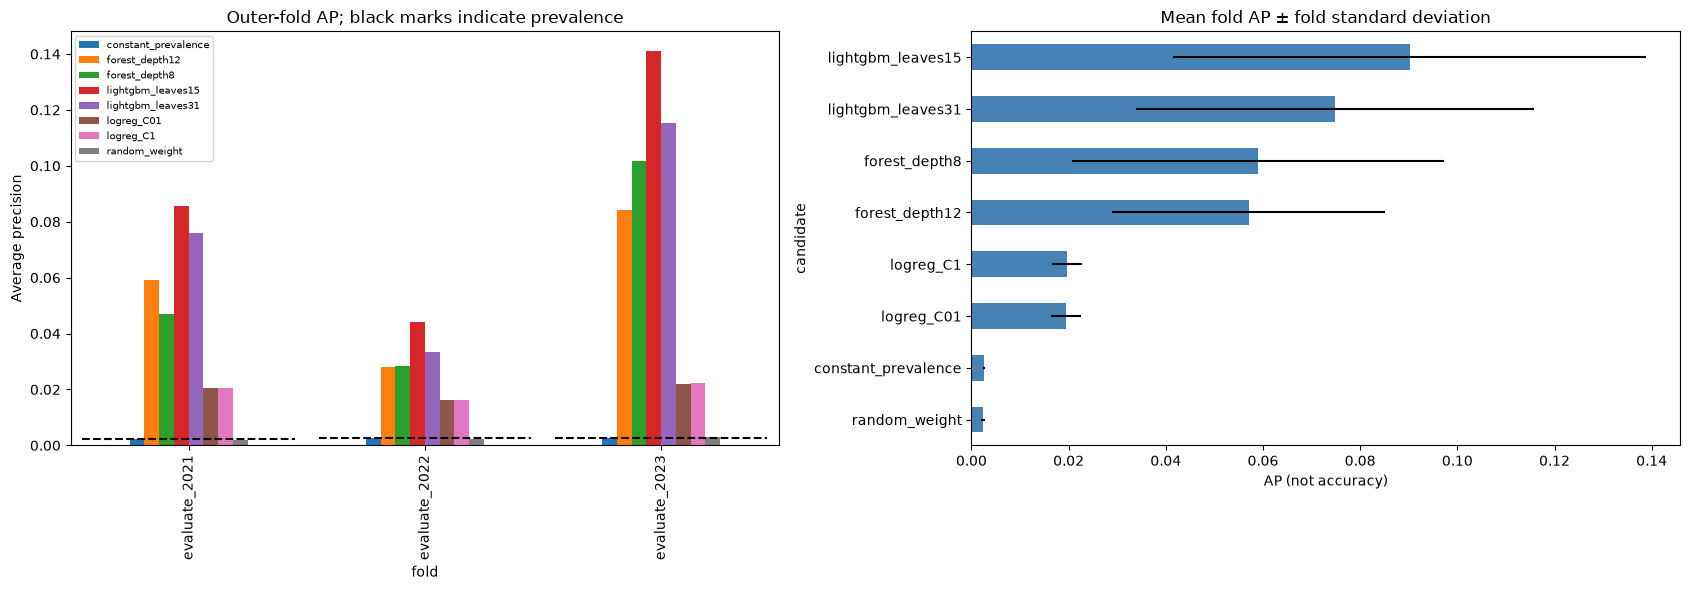

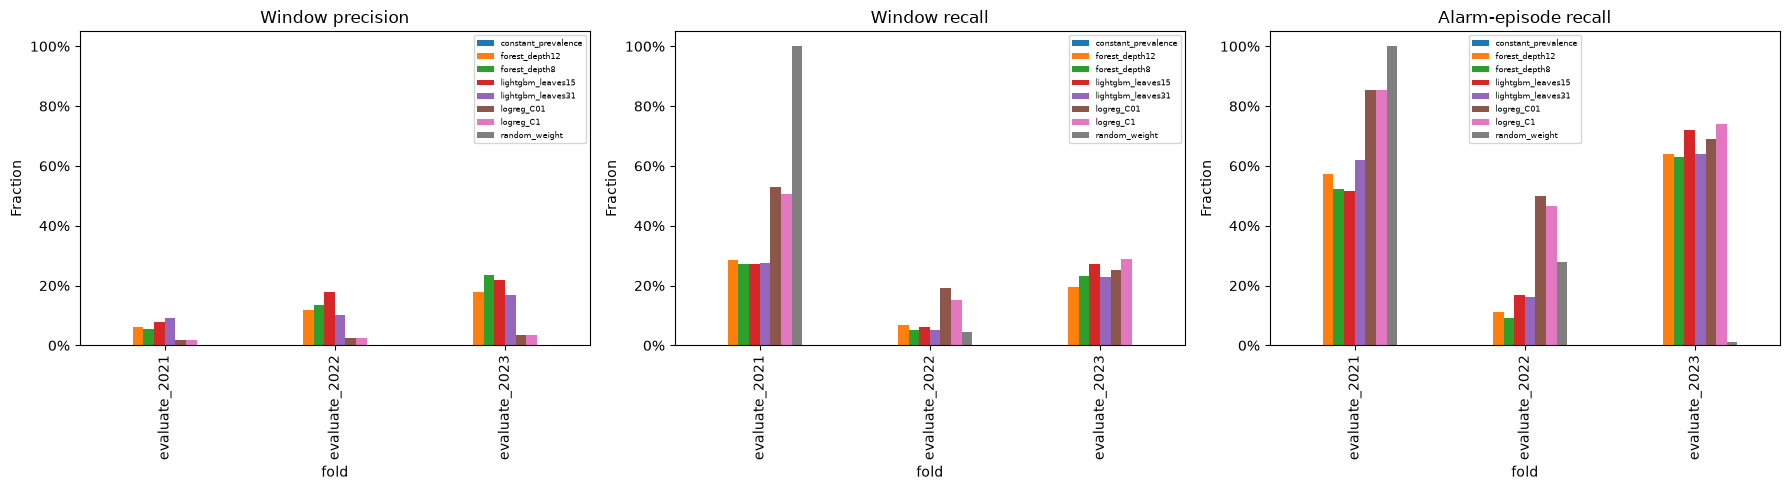

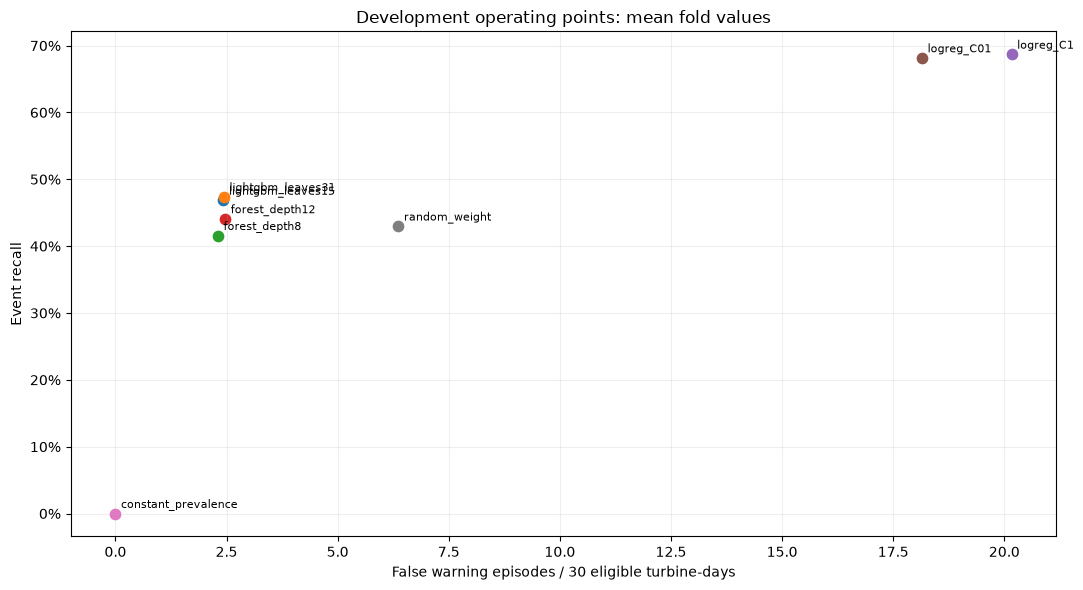

In [6]:
# AP ranking and variation across time, with the fold-specific prevalence floor.
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fold_metrics.pivot(index='fold', columns='candidate', values='AP').plot.bar(ax=axes[0])
floors = fold_metrics.groupby('fold').prevalence.first()
for i, fold in enumerate(fold_metrics.pivot(index='fold', columns='candidate', values='AP').index):
    axes[0].hlines(floors.loc[fold], i - .45, i + .45, color='black', linestyle='--', linewidth=1.5)
axes[0].set(title='Outer-fold AP; black marks indicate prevalence', ylabel='Average precision')
axes[0].legend(fontsize=7)
comparison.set_index('candidate').mean_AP.plot.barh(ax=axes[1], xerr=comparison.sd_AP.fillna(0).to_numpy(), color='steelblue')
axes[1].invert_yaxis()
axes[1].set(title='Mean fold AP Â± fold standard deviation', xlabel='AP (not accuracy)')
show_figure(fig, 'ap_comparison')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric, label in zip(axes, ['precision', 'recall', 'event_recall'],
                            ['Window precision', 'Window recall', 'Alarm-episode recall'], strict=False):
    fold_metrics.pivot(index='fold', columns='candidate', values=metric).plot.bar(ax=ax)
    ax.set(title=label, ylabel='Fraction', ylim=(0, 1.05))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=6)
show_figure(fig, 'precision_recall_by_fold')

fig, ax = plt.subplots(figsize=(11, 6))
for _, row in comparison.iterrows():
    ax.scatter(row.mean_false_warning_episode_rate, row.mean_event_recall, s=55)
    ax.annotate(row.candidate, (row.mean_false_warning_episode_rate, row.mean_event_recall),
                xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.set(title='Development operating points: mean fold values',
       xlabel='False warning episodes / 30 eligible turbine-days', ylabel='Event recall')
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.grid(alpha=.2)
show_figure(fig, 'false_warnings_vs_event_recall')


Candidate for detailed turbine review: lightgbm_leaves15
Final refit frozen: True
Frozen champion: lightgbm_leaves15
Final threshold source: 2021-2023 out-of-fold development predictions
The following CV metrics still use each fold’s own inner-calibrated threshold, not the final-refit threshold.
Undefined ratios mean no denominator, not a measured zero.


,evaluated_folds,folds_with_defined_AP,mean_AP,mean_prevalence,rows,positive_windows,TP,FP,FN,eligible_episodes,detected_episodes,combined_precision,combined_event_recall
turbine,,,,,,,,,,,,,
2304510,3,3,0.071625,0.004021,153675,615,60,708,555,27,7,0.078125,0.259259
2304511,3,3,0.234982,0.001948,154495,302,121,324,181,12,9,0.271910,0.750000
2304512,3,3,0.078813,0.002763,153678,425,70,521,355,21,7,0.118443,0.333333
2304513,3,3,0.167355,0.003342,154546,519,142,737,377,20,11,0.161547,0.550000
2304514,3,2,0.129179,0.002093,154273,327,82,423,245,13,7,0.162376,0.538462
2304515,3,2,0.130769,0.000916,148352,144,61,425,83,4,3,0.125514,0.750000
2304516,3,3,0.145943,0.005406,153718,830,158,1276,672,34,18,0.110181,0.529412
2304517,3,3,0.119130,0.003685,153682,570,102,832,468,38,8,0.109208,0.210526
2304518,3,3,0.079559,0.000949,155436,148,60,708,88,6,4,0.078125,0.666667


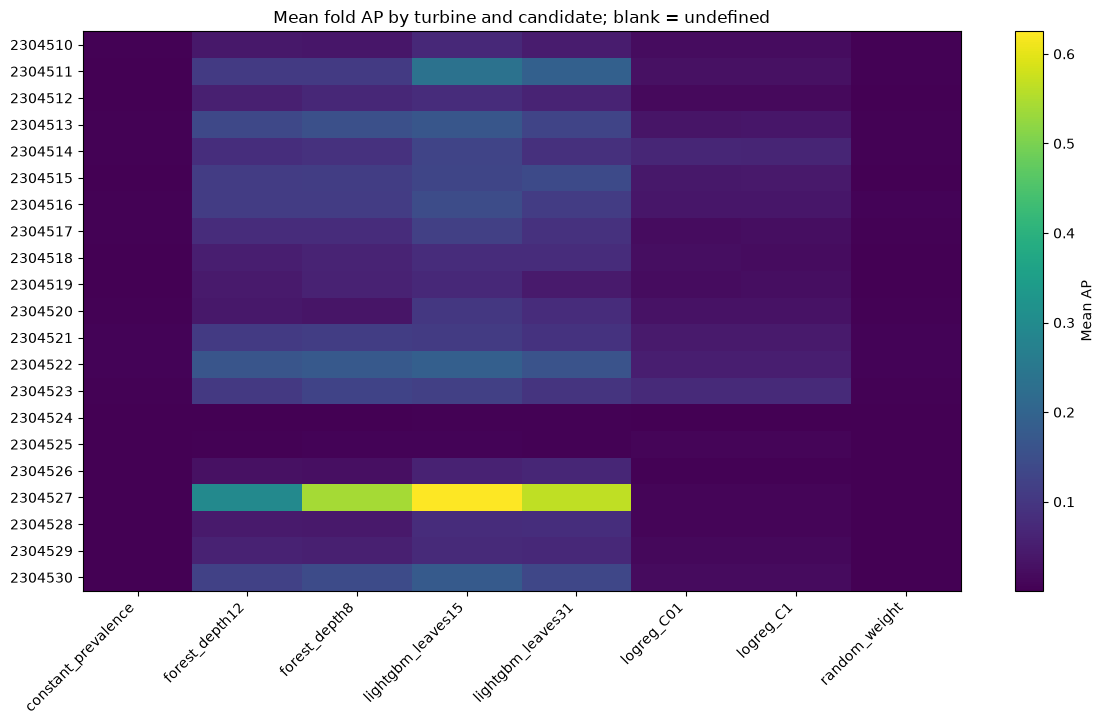

In [7]:
# Show saved final selection metadata without loading any fitted models or reserved scores.
frozen_path = ACTIVE_RUN / 'final' / 'frozen_configuration.json'
frozen_metadata = json.loads(frozen_path.read_text(encoding='utf-8')) if frozen_path.is_file() else {}
if DETAIL_CANDIDATE is not None:
    detail_candidate = DETAIL_CANDIDATE
elif frozen_metadata.get('champion') in chosen:
    detail_candidate = frozen_metadata['champion']
else:
    detail_candidate = comparison.iloc[0].candidate
if detail_candidate not in chosen:
    raise ValueError(f'DETAIL_CANDIDATE must be one of {chosen}')
print('Candidate for detailed turbine review:', detail_candidate)
print('Final refit frozen:', bool(frozen_metadata))
if frozen_metadata:
    print('Frozen champion:', frozen_metadata.get('champion'))
    print('Final threshold source:', frozen_metadata.get('threshold_source'))
    print('The following CV metrics still use each foldâ€™s own inner-calibrated threshold, not the final-refit threshold.')

selected_turbines = per_turbine.loc[per_turbine.candidate.eq(detail_candidate)]
turbine_summary = selected_turbines.groupby('turbine').agg(
    evaluated_folds=('fold', 'nunique'), folds_with_defined_AP=('AP', 'count'),
    mean_AP=('AP', 'mean'), mean_prevalence=('prevalence', 'mean'),
    rows=('rows', 'sum'), positive_windows=('positives', 'sum'), TP=('TP', 'sum'),
    FP=('FP', 'sum'), FN=('FN', 'sum'), eligible_episodes=('eligible_alarm_episodes', 'sum'),
    detected_episodes=('detected_alarm_episodes', 'sum'))
turbine_summary['combined_precision'] = turbine_summary.TP / (turbine_summary.TP + turbine_summary.FP).replace(0, np.nan)
turbine_summary['combined_event_recall'] = turbine_summary.detected_episodes / turbine_summary.eligible_episodes.replace(0, np.nan)
display(turbine_summary.round(6))
print('Undefined ratios mean no denominator, not a measured zero.')

heat = per_turbine.pivot_table(index='turbine', columns='candidate', values='AP', aggfunc='mean', dropna=False)
fig, ax = plt.subplots(figsize=(12, max(5, .35 * len(heat))))
image = ax.imshow(np.ma.masked_invalid(heat.to_numpy()), aspect='auto', interpolation='nearest')
ax.set(yticks=range(len(heat)), yticklabels=heat.index, xticks=range(len(heat.columns)),
       xticklabels=heat.columns, title='Mean fold AP by turbine and candidate; blank = undefined')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
fig.colorbar(image, ax=ax, label='Mean AP')
show_figure(fig, 'per_turbine_ap')


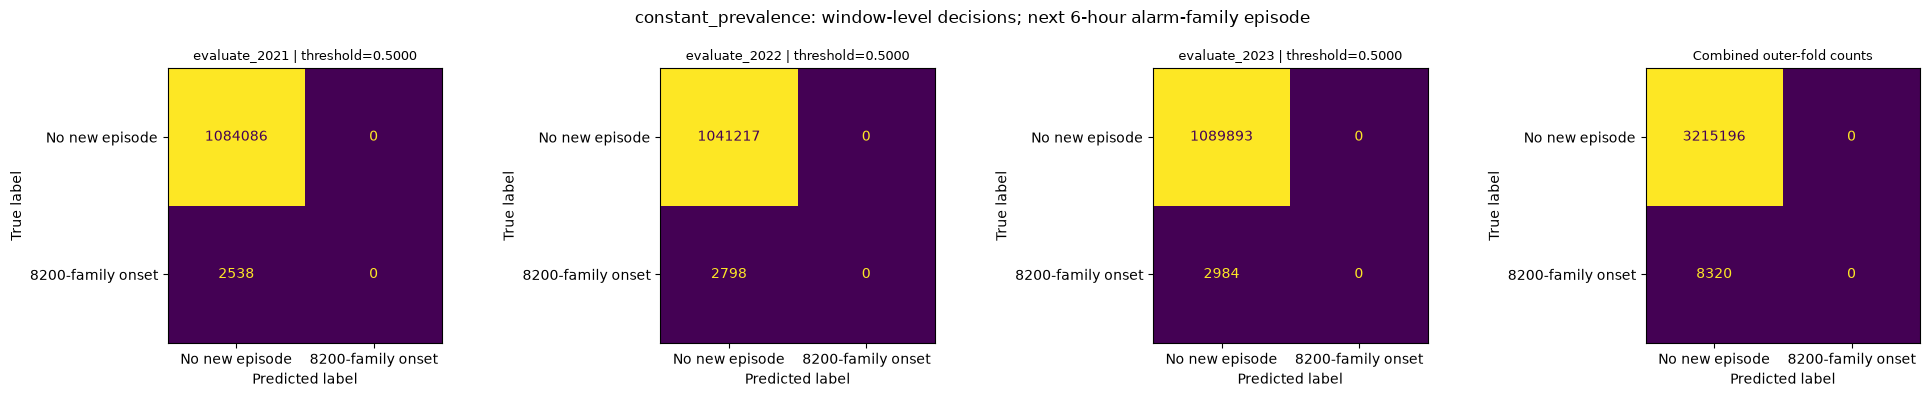

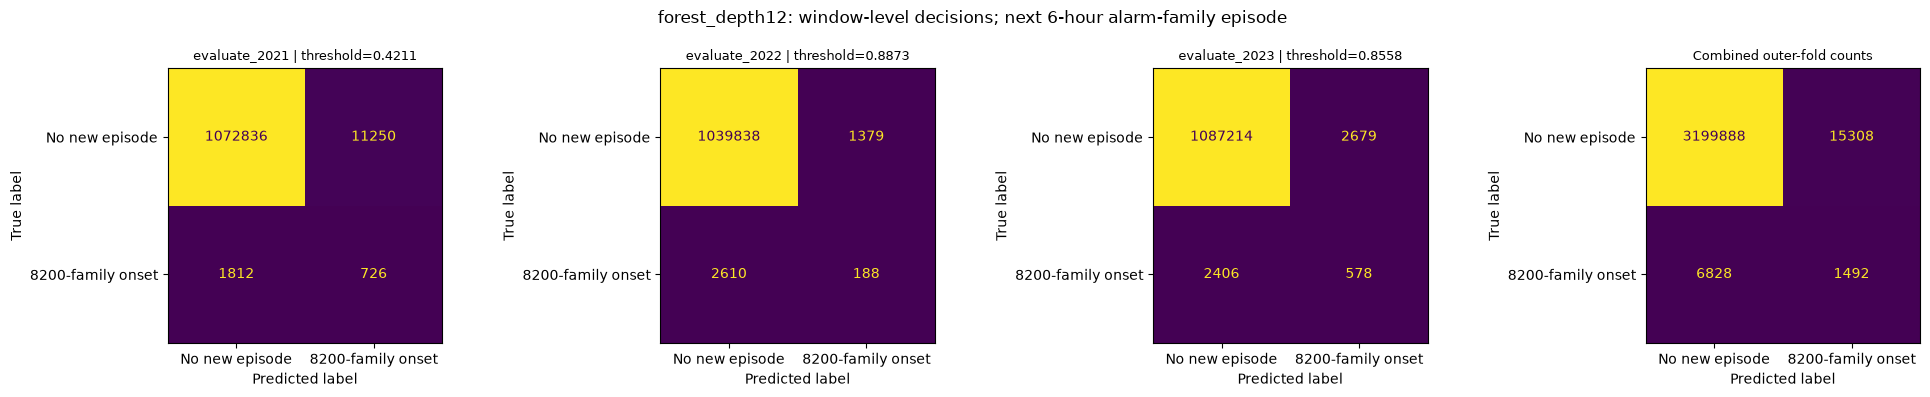

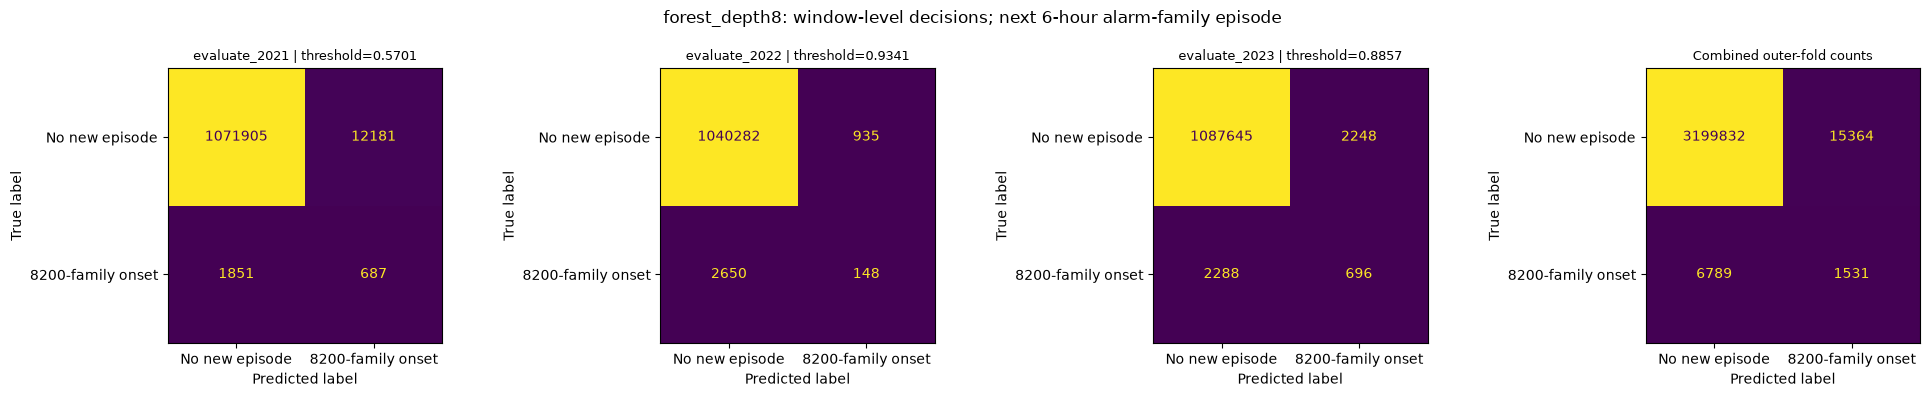

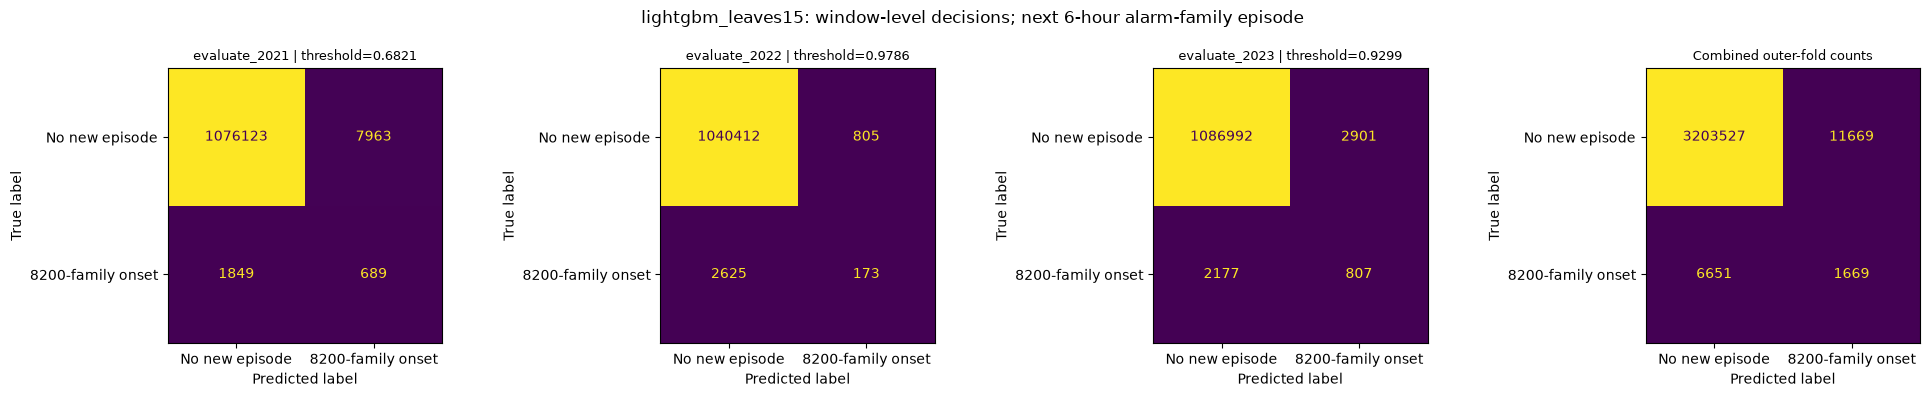

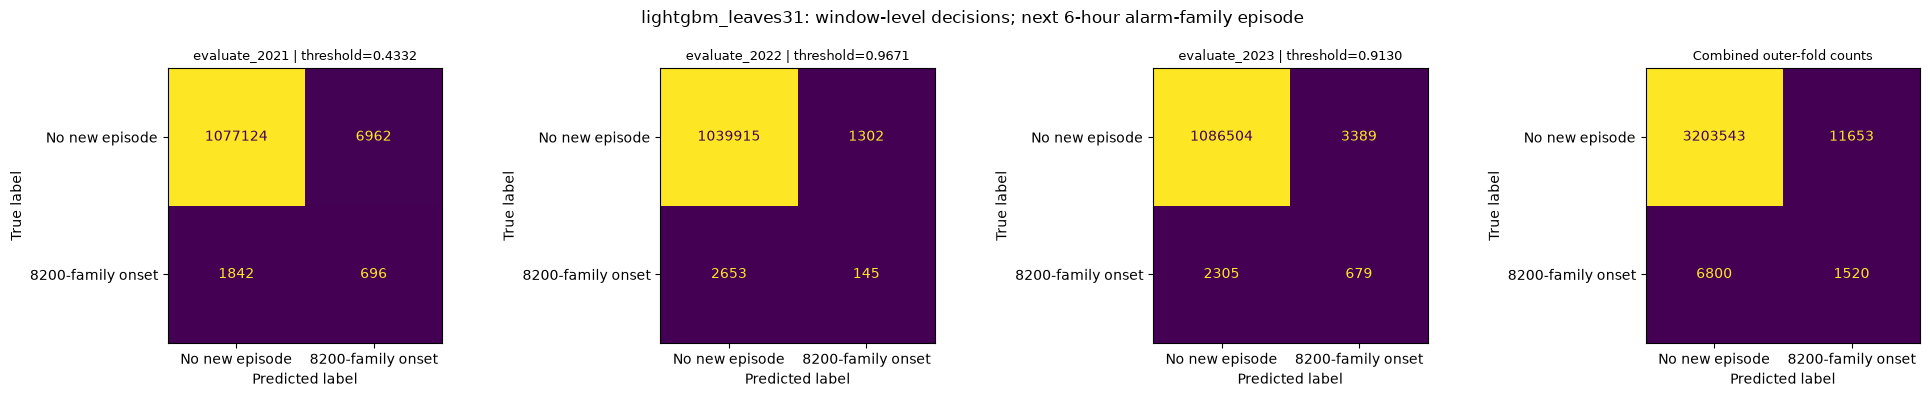

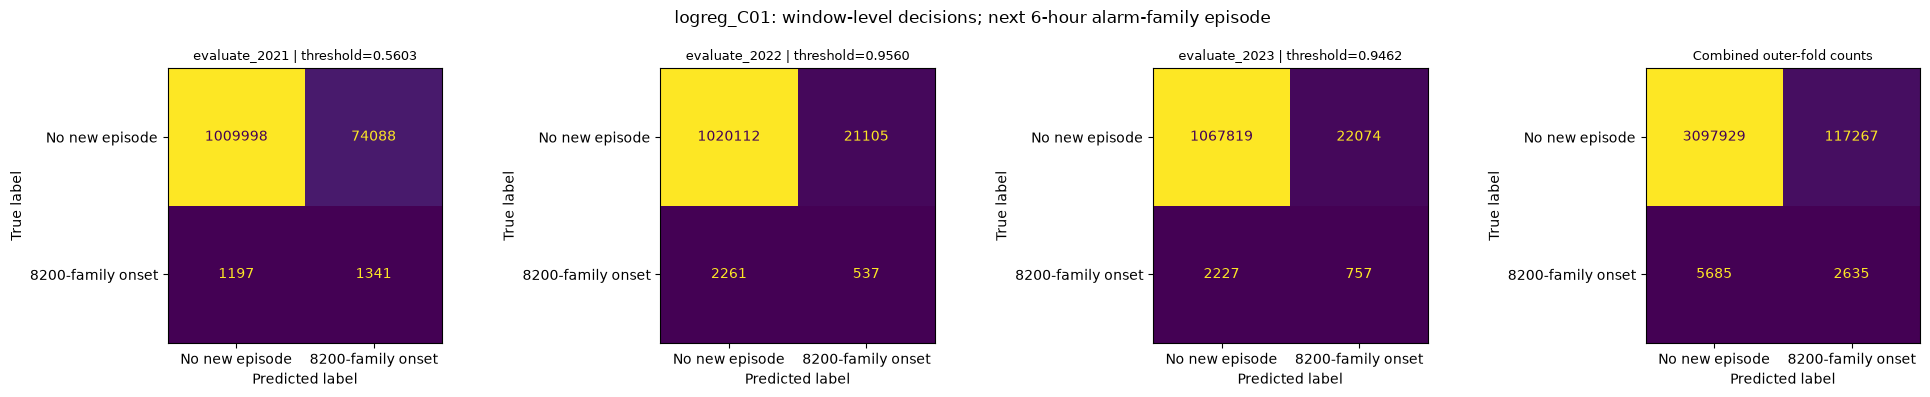

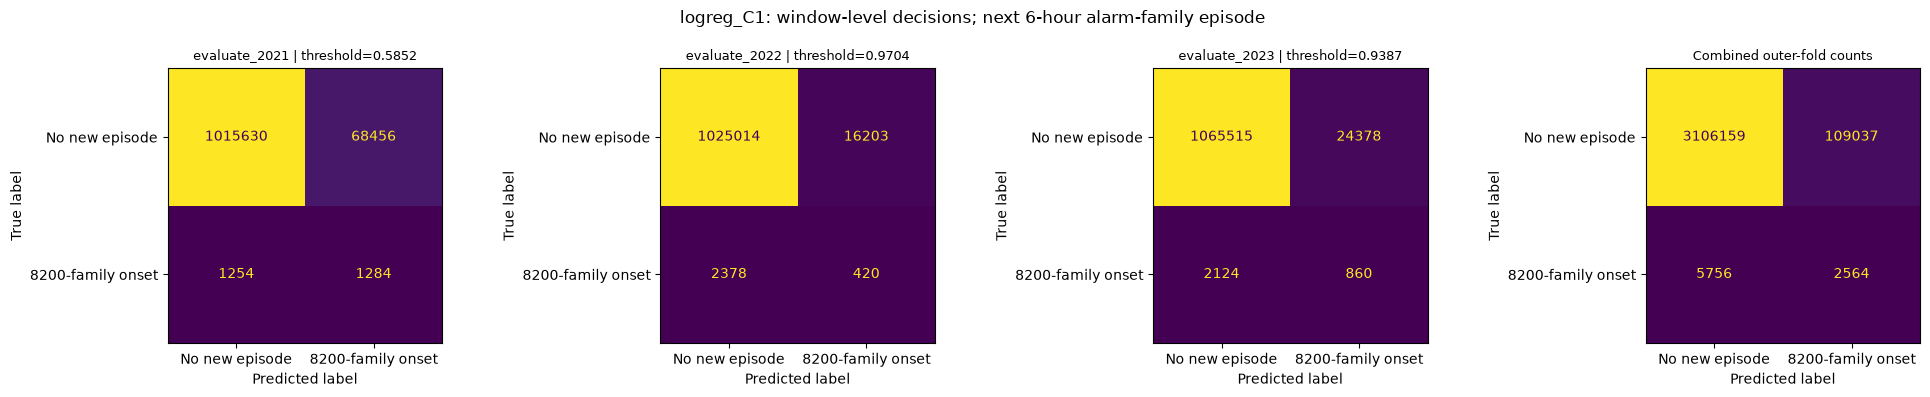

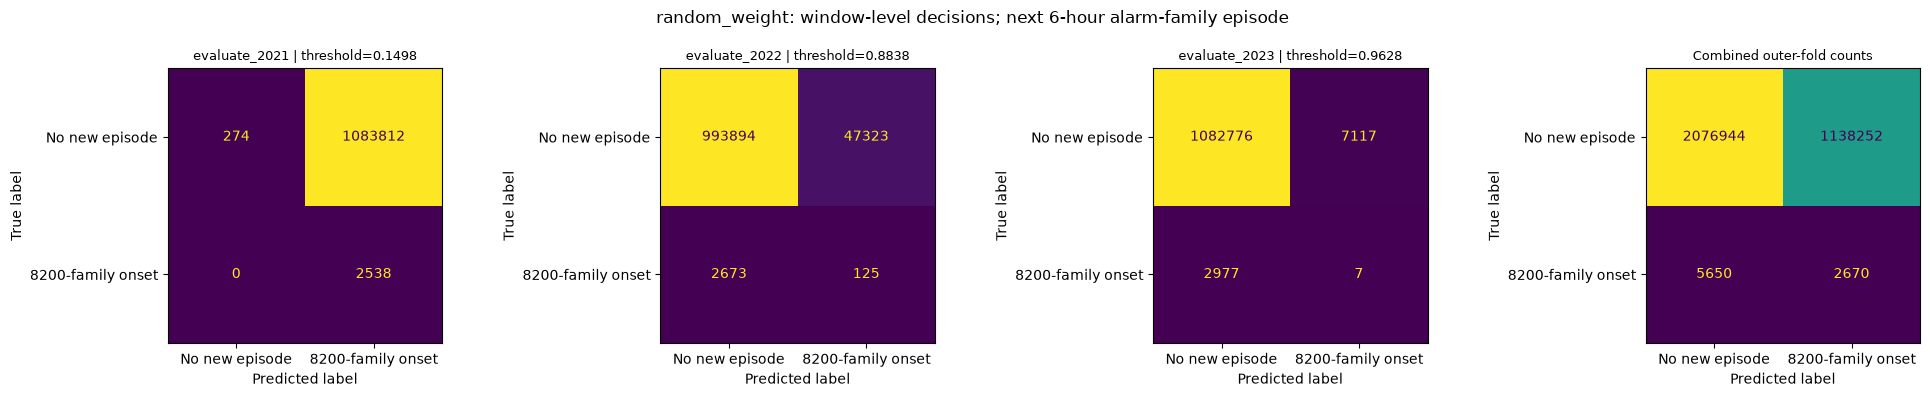

In [8]:
# Confusion matrices come directly from saved counts: no prediction files needed.
confusion_candidates = chosen if SHOW_ALL_CONFUSION_MATRICES else [detail_candidate]
for name in confusion_candidates:
    rows = fold_metrics.loc[fold_metrics.candidate.eq(name)].sort_values('fold')
    fig, axes = plt.subplots(1, len(rows) + 1, figsize=(5 * (len(rows) + 1), 4))
    total = np.zeros((2, 2), dtype='int64')
    for ax, row in zip(axes[:-1], rows.itertuples(index=False), strict=False):
        matrix = np.array([[row.TN, row.FP], [row.FN, row.TP]], dtype='int64')
        total += matrix
        ConfusionMatrixDisplay(matrix, display_labels=['No new episode', '8200-family onset']).plot(
            ax=ax, colorbar=False, values_format='d')
        ax.set_title(f'{row.fold} | threshold={row.threshold:.4f}', fontsize=9)
    ConfusionMatrixDisplay(total, display_labels=['No new episode', '8200-family onset']).plot(
        ax=axes[-1], colorbar=False, values_format='d')
    axes[-1].set_title('Combined outer-fold counts', fontsize=9)
    fig.suptitle(f'{name}: window-level decisions; next 6-hour alarm-family episode')
    show_figure(fig, f'confusion_{name}')


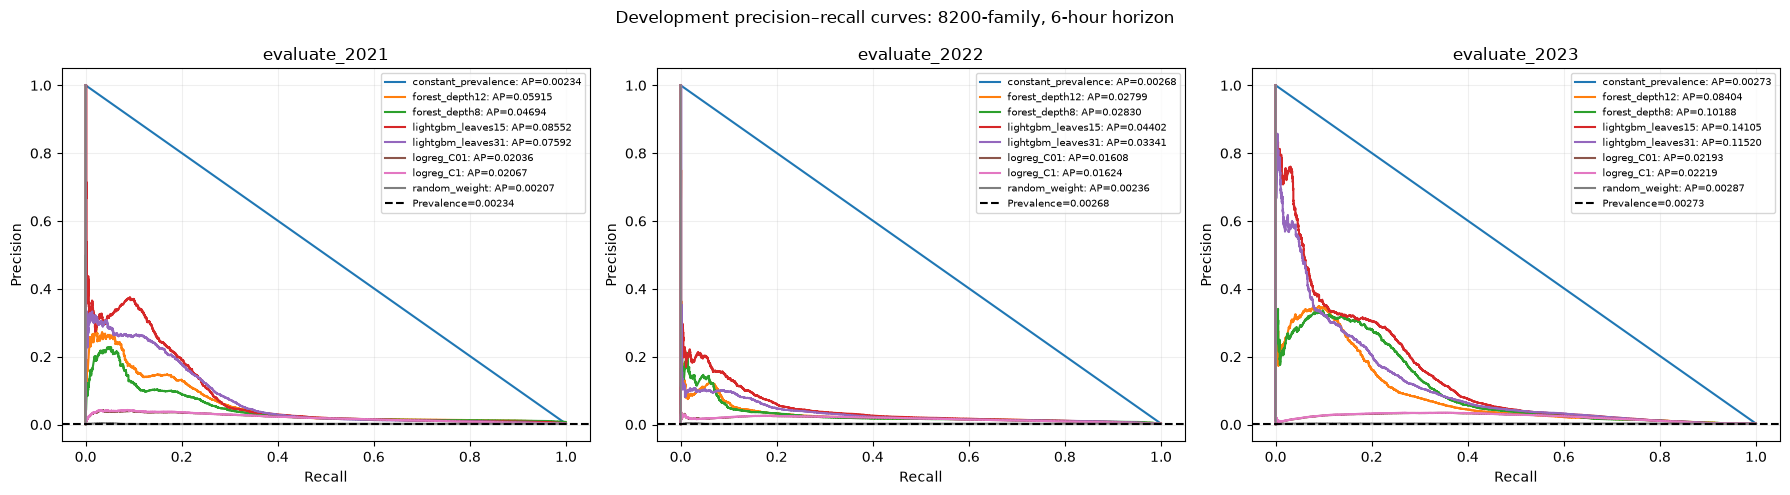

In [9]:
# Optional PR curves read saved DEVELOPMENT predictions in cv/oof only.
# This can take longer than reading the summary CSVs, but never retrains models.
if PLOT_PRECISION_RECALL:
    folds = sorted(fold_metrics.fold.unique())
    fig, axes = plt.subplots(1, len(folds), figsize=(6 * len(folds), 5), squeeze=False)
    missing_predictions = []
    for ax, fold in zip(axes[0], folds, strict=False):
        for name in chosen:
            path = ACTIVE_RUN / 'cv' / 'oof' / name / f'{fold}.parquet'
            if not path.resolve().is_relative_to((ACTIVE_RUN / 'cv' / 'oof').resolve()):
                raise ValueError('Invalid saved prediction path.')
            if not path.is_file():
                missing_predictions.append(str(path)); continue
            prediction = pd.read_parquet(path, columns=['target', 'score'])
            precision, recall, _ = precision_recall_curve(prediction.target, prediction.score, drop_intermediate=True)
            ap = average_precision_score(prediction.target, prediction.score)
            ax.plot(recall, precision, label=f'{name}: AP={ap:.5f}')
            del prediction
        prevalence = fold_metrics.loc[fold_metrics.fold.eq(fold), 'prevalence'].iloc[0]
        ax.axhline(prevalence, color='black', linestyle='--', label=f'Prevalence={prevalence:.5f}')
        ax.set(title=fold, xlabel='Recall', ylabel='Precision'); ax.legend(fontsize=7)
        ax.grid(alpha=.2)
    fig.suptitle('Development precisionâ€“recall curves: 8200-family, 6-hour horizon')
    show_figure(fig, 'precision_recall_curves')
    if missing_predictions:
        print('Unavailable saved OOF files (CSV evaluation remains usable):', missing_predictions)
else:
    print('PR curves skipped. All displayed tables and confusion matrices use the saved CSVs.')


In [10]:
# Optional development dataset context: these audits contain no reserved-year evaluation.
for filename in ['development_data_audit.csv', 'development_code_counts.csv']:
    path = ACTIVE_RUN / filename
    if not path.is_file():
        print('Audit unavailable:', filename); continue
    audit = pd.read_csv(path, dtype={'turbine': str})
    if filename == 'development_data_audit.csv':
        display(Markdown('**Development data availability by year**'))
        display(audit.groupby('year').agg(turbine_ids=('turbine', 'nunique'),
            eligible_windows=('eligible_rows', 'sum'), positive_windows=('positive_windows', 'sum'),
            duplicates_removed=('exact_duplicates_removed', 'sum')))
        excluded = audit.loc[audit.eligible_rows.eq(0), ['year', 'turbine', 'observed_sensor_rows']]
        if not excluded.empty:
            print('Turbine-years without eligible sensor histories:'); display(excluded)
    else:
        display(Markdown('**Deduplicated 8200-family development starts by code**'))
        display(audit.groupby('code').starts.sum().to_frame())
print('Finished: no training, model loading, threshold changes, or reserved-test data access.')


Turbine-years without eligible sensor histories:
Finished: no training, model loading, threshold changes, or reserved-test data access.


**Development data availability by year**

,turbine_ids,eligible_windows,positive_windows,duplicates_removed
year,,,,
2016,21,1094479,1764,0
2017,22,1082532,3457,0
2018,22,1090524,1066,0
2020,21,1099262,992,0
2021,22,1086624,2538,0
2022,22,1044015,2798,0
2023,22,1092877,2984,0


,year,turbine,observed_sensor_rows
42,2017,91,0
64,2018,91,0
107,2021,91,0
129,2022,91,0
151,2023,91,0


**Deduplicated 8200-family development starts by code**

,starts
code,
8228,44
8230,483
8232,35
8260,70


## Interpretation checklist

1. Compare AP with prevalence and the constant/random baselines; high ROC-AUC alone does not establish useful warnings.
2. Check false positives, warning fraction and event recall together. Many positive windows can come from one episode.
3. Inspect fold variation and individual turbines before drawing a wind-farm-wide conclusion.
4. Mean fold AP, mean turbine AP and ratios computed from combined counts are different summaries; they are labelled separately here.
5. These are development comparisons used for selection. Final testing of frozen models on 2024â€“2025 remains a separate, explicitly enabled operation in the training notebook. Those years were inspected in earlier work and are not historically pristine holdouts.
6. Rerun this notebook to refresh after a training run finishes. Set RUN_ID to compare a specific run; this viewer never replaces saved training results. SAVE_FIGURES, if enabled, writes only to reports/cv_evaluation_views/.
